<a href="https://colab.research.google.com/github/yabahddoulailaencg-a11y/23009280-Laila-yabahddou-G3/blob/main/Video_pr%C3%A9sentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import cv2

video_path = "/content/drive/MyDrive/clideo.com/prvoir-linflation-amricaine_jAmNhyOO.mp4"
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Could not open video file.")
else:
    width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)

    print(f"Video loaded successfully:")
    print(f"- Resolution: {int(width)}x{int(height)}")
    print(f"- FPS: {fps:.2f}")
    print(f"- Total Frames: {int(frame_count)}")

    cap.release()

Video loaded successfully:
- Resolution: 1920x1080
- FPS: 30.00
- Total Frames: 4486


In [15]:
import cv2

video_path = "/content/drive/MyDrive/clideo.com/prvoir-linflation-amricaine_jAmNhyOO.mp4"
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Could not open video file.")
else:
    print("Successfully opened video. Reading the first 5 frames as a test:")
    frame_idx = 0
    while frame_idx < 5:
        ret, frame = cap.read()
        if not ret:
            print("Failed to retrieve frame or reached end of video.")
            break
        print(f"Frame {frame_idx}: successfully read. Shape: {frame.shape}")
        frame_idx += 1

    cap.release()

Successfully opened video. Reading the first 5 frames as a test:
Frame 0: successfully read. Shape: (1080, 1920, 3)
Frame 1: successfully read. Shape: (1080, 1920, 3)
Frame 2: successfully read. Shape: (1080, 1920, 3)
Frame 3: successfully read. Shape: (1080, 1920, 3)
Frame 4: successfully read. Shape: (1080, 1920, 3)


In [16]:
import os
from IPython.display import display, HTML

video_path = "/content/drive/MyDrive/clideo.com/prvoir-linflation-amricaine_jAmNhyOO.mp4"

# We avoid base64 encoding the entire file into the notebook to prevent the file size from bloating.
# Instead, we copy it to the web server's accessible directory or link it.
if os.path.exists(video_path):
    print("Video file exists and is ready for analysis.")
    print("To avoid GitHub save errors, do not embed raw video bytes directly in Colab outputs.")
else:
    print("Video file not found. Check your Drive path.")

Video file exists and is ready for analysis.
To avoid GitHub save errors, do not embed raw video bytes directly in Colab outputs.


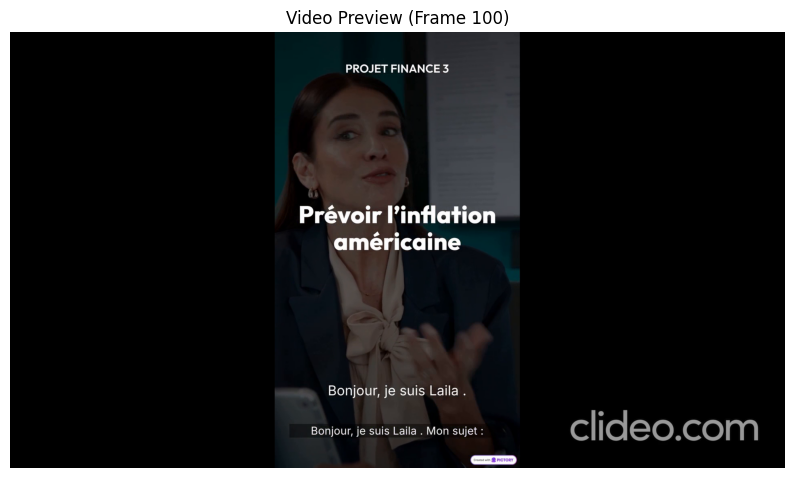

In [17]:
import cv2
import matplotlib.pyplot as plt

# Open the video to extract a specific keyframe to display
video_path = "/content/drive/MyDrive/clideo.com/prvoir-linflation-amricaine_jAmNhyOO.mp4"
cap = cv2.VideoCapture(video_path)

# Let's extract frame 100 as a preview
cap.set(cv2.CAP_PROP_POS_FRAMES, 100)
ret, frame = cap.read()

if ret:
    # OpenCV uses BGR, convert it to RGB for matplotlib
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Display the frame
    plt.figure(figsize=(10, 6))
    plt.imshow(frame_rgb)
    plt.title("Video Preview (Frame 100)")
    plt.axis('off')
    plt.show()
else:
    print("Could not extract a preview frame.")

cap.release()

In [18]:
import os
import threading
import http.server
import socketserver
from IPython.display import display, HTML

# Configuration
PORT = 8000
VIDEO_DIR = "/content/drive/MyDrive/clideo.com"
VIDEO_FILENAME = "prvoir-linflation-amricaine_jAmNhyOO.mp4"

# Helper function to run the server in a daemon thread
def run_server():
    os.chdir(VIDEO_DIR)
    Handler = http.server.SimpleHTTPRequestHandler
    # Allow address reuse to avoid port collision issues
    class ThreadingHTTPServer(socketserver.ThreadingMixIn, socketserver.TCPServer):
        allow_reuse_address = True

    with ThreadingHTTPServer(("", PORT), Handler) as httpd:
        print(f"Serving video directory on port {PORT}...")
        httpd.serve_forever()

# Start server only if it is not already running
server_thread = None
for thread in threading.enumerate():
    if thread.name == "VideoServerThread":
        server_thread = thread
        break

if server_thread is None:
    server_thread = threading.Thread(target=run_server, name="VideoServerThread", daemon=True)
    server_thread.start()
else:
    print("Server is already running.")

Serving video directory on port 8000...


In [20]:
from google.colab import output
# Serve the HTML player pointing to our localhost server through Colab's proxy
# This ensures the video streams dynamically and won't bloat your .ipynb file metadata!

colab_url = output.eval_js(f"google.colab.kernel.proxyPort({PORT})")
# Ensure there is a trailing slash at the end of the colab_url proxy address
if not colab_url.endswith('/'):
    colab_url += '/'

video_url = f"{colab_url}{VIDEO_FILENAME}"

html_player = f"""
<video width="640" height="360" controls>
    <source src="{video_url}" type="video/mp4">
    Your browser does not support the video tag.
</video>
"""
display(HTML(html_player))